<a href="https://colab.research.google.com/github/MBR4V0/Python/blob/main/SHAP_VGC16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install -q -U shap

In [8]:
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import shap

from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("SHAP:", shap.__version__)


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow: 2.20.0
SHAP: 0.52.0


In [9]:
model = VGG16(
    weights="imagenet",
    include_top=True
)

print("VGG16 carregada.")


VGG16 carregada.


In [10]:
X, y = shap.datasets.imagenet50()

X = X.astype(np.float32)

to_explain = X[[39, 41]]

print("X:", X.shape)
print("to_explain:", to_explain.shape)


X: (50, 224, 224, 3)
to_explain: (2, 224, 224, 3)


In [11]:
url = "https://s3.amazonaws.com/deep-learning-models/image-models/imagenet_class_index.json"

with open(shap.datasets.cache(url), "r") as f:
    class_index = json.load(f)

class_names = [class_index[str(i)][1] for i in range(1000)]


In [12]:
def predict(images):
    images = np.asarray(images, dtype=np.float32)

    images = preprocess_input(images.copy())

    return model.predict(
        images,
        verbose=0
    )


In [13]:
predictions = predict(to_explain)

top2 = np.argsort(
    predictions,
    axis=1
)[:, -2:][:, ::-1]

for i in range(len(to_explain)):

    print(f"\nImagem {i + 1}")

    for rank, class_id in enumerate(top2[i], 1):

        print(
            f"{rank}. "
            f"{class_names[class_id]} — "
            f"{predictions[i, class_id] * 100:.2f}%"
        )



Imagem 1
1. dowitcher — 98.67%
2. red-backed_sandpiper — 0.60%

Imagem 2
1. meerkat — 95.78%
2. mongoose — 4.22%


**SHAP MODERNO**

In [19]:
masker = shap.maskers.Image(
    "blur(16,16)",
    to_explain[0].shape
)

explainer = shap.Explainer(
    predict,
    masker,
    output_names=class_names
)

print("SHAP Explainer criado.")


SHAP Explainer criado.


In [20]:
shap_values = explainer(
    to_explain,
    max_evals=500,
    batch_size=10,
    outputs=shap.Explanation.argsort.flip[:2]
)

print("Explicação SHAP concluída.")


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  50%|█████     | 1/2 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 3it [07:25, 222.65s/it]

Explicação SHAP concluída.


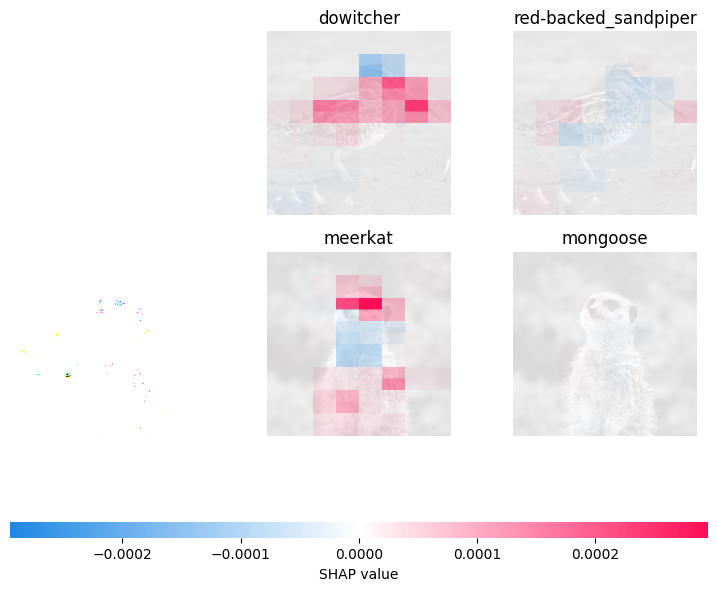

In [21]:
shap.image_plot(shap_values)
